# Week 5 · Finding a tidal disruption event: hand-in

**Science objective:** search the Rubin alert stream for tidal disruption event
candidates, by choosing the selection criteria yourself and defending the choice.

On Wednesday you searched DP2 for an optical counterpart to the gravitational-wave
candidate S251112cm. That search had a trigger: a time and a place to look. It kept
objects evolving faster than 0.05 mag/day and **discarded everything slower**.

A tidal disruption event lives in the bin that search threw away. A star passing inside
the tidal radius of a supermassive black hole is pulled apart, and the debris accretes
over months. There is no trigger, so the selection has to come from the light curve and
the position instead:

| criterion | why |
|---|---|
| **persistently blue** | the emitting gas sits at 2-4 x 10^4 K for months, so `g-r` stays negative and does not redden |
| **nuclear** | the disruption happens at the black hole, so the flare sits on the galaxy's centre |
| **not an AGN, not a star** | accreting black holes are blue, variable and nuclear too; cataclysmic variables are blue and point-like |

The filter below is written for you. **What is not written for you are the numbers**:
how blue is blue enough, how long is long enough, how close to the nucleus counts as
nuclear. Each exercise asks you to set one group of thresholds from what you know about
how transients behave, then show what your choice does.

### What to hand in

Work through **all four exercises** - each sets one group of thresholds, and together
they are one selection. Then turn in **this notebook** with:

1. **one figure**, with a panel from each exercise. The hand-in cell has a 2x2 scaffold.
2. **one paragraph** covering the whole search: the thresholds you chose, why those
   values follow from the physics, and what the selection cost you. **Quote at least one
   number read off your figure.**
3. the **AI-tools line** in the last cell filled in.

Graded complete/incomplete. The *Go further* boxes are optional and do not change your
grade.

You need a Babamul API token in a `.env` file next to this notebook; see
`.env.example`.

## Before you start

**Packages.** Everything the notebook imports is in `requirements.txt`:

```bash
pip install -r requirements.txt
```

On Colab, `astropy`, `matplotlib`, `numpy` and `tqdm` are already there, so:

```python
!pip install babamul python-dotenv ipywidgets
```

The import name is `dotenv` but the package is **`python-dotenv`**. There is a separate
PyPI package called `dotenv` and it is not the one you want. `ipywidgets` is not
optional: the notebook imports `babamul.jupyter`, which imports it at module level.

**Credentials.** This notebook reads alerts through Babamul's API, so you need one
value: your **API token**. Get it from
[babamul.caltech.edu/profile](https://babamul.caltech.edu/profile), then from a
terminal next to this notebook:

```bash
cp .env.example .env
```

and put the token in the `BABAMUL_API_TOKEN` line, so `.env` reads:

```
BABAMUL_API_TOKEN=bbml_...
```

Babamul also issues a separate Kafka username and password, for streaming alerts live.
**You do not need those here** - this notebook queries a fixed window of past alerts
instead, so that everyone works on the same sky. If a cell ever asks for a Kafka
credential, you are running the wrong cell.

`.env` holds a credential, so do not commit it or paste it into a cell. On Colab there
is no terminal by default; either use the file browser to upload a `.env`, or set the
variable directly with `os.environ["BABAMUL_API_TOKEN"] = getpass.getpass()`.

**Check it worked.** The next cell confirms the packages and the token before the slow
query in Setup. Run it first - it takes a second, and it turns a confusing failure
later into an obvious one now.

In [1]:
import importlib.metadata as metadata
import os

import dotenv

REQUIRED = ("astropy", "babamul", "ipywidgets", "matplotlib", "numpy",
            "python-dotenv", "tqdm")

installed = {dist.metadata["Name"].lower(): dist.version
             for dist in metadata.distributions() if dist.metadata["Name"]}
print("packages")
for package in REQUIRED:
    version = installed.get(package.lower())
    print(f"   {package:>14} {version or 'MISSING -- pip install ' + package}")

path = dotenv.find_dotenv(usecwd=True)
dotenv.load_dotenv(path)
token = os.environ.get("BABAMUL_API_TOKEN")
print(f"\n.env file: {path or 'NOT FOUND -- copy .env.example to .env'}")
print(f"BABAMUL_API_TOKEN: "
      f"{str(len(token)) + ' characters' if token else 'NOT SET'}")

# One cheap authenticated call. A bad token raises here rather than 80 seconds later.
import babamul
print(f"\nAPI token works: authenticated as {babamul.api.get_profile().username}")

packages
          astropy 8.0.2
          babamul 0.1.0
       ipywidgets 8.1.9
       matplotlib 3.11.2
            numpy 2.2.6
    python-dotenv 1.2.4
             tqdm 4.70.1

.env file: /oak/stanford/orgs/kipac/users/jsomalwa/rubin_transient_lecture/homework_tde/.env
BABAMUL_API_TOKEN: 41 characters

API token works: authenticated as jsomalwar


**Words you will meet.** *Difference image*: the new exposure minus a deep template, so
only what changed is left. All photometry here is difference photometry, which is why
the colours are the transient's and not the host galaxy's. *diaObject*: one variable
source, with all its detections. *Alert*: one detection of one diaObject in one visit.
*Real-bogus* (`drb`, `reliability`): a classifier score for whether a detection is a
real astrophysical source rather than a subtraction artefact. *Extendedness*: 0 for a
point source, 1 for a resolved one. *LSPSC*: the Legacy Survey point-source catalogue;
its `score` separates stars from everything else - see the Setup cell that measures what
it does, because it is not a probability and runs from 0 to 2. *Milliquas*: a compilation of known quasars. *Nuclear*:
coincident with the centre of a galaxy. *Flare age*: days between an object's first
recorded detection and now.

## Setup

Everything in this section is given. Run it and move on to the exercises; it takes about
a minute, most of which is one query.

The vetoes are the same ones you applied on Wednesday - AllWISE `W1-W2 >= 0.8`,
Milliquas, Gaia astrometry - but the broker has already done the cross-matching, so here
they are a field lookup rather than a VizieR query.

*From the tutorial:* `DP2_transients_in_S251112cm.ipynb`, sections 4.1 to 4.3.

In [2]:
import os
import shutil

import dotenv
import matplotlib
import matplotlib.font_manager
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.modeling.physical_models import BlackBody
from astropy.table import Table
from tqdm.notebook import tqdm

import babamul
import babamul.jupyter

dotenv.load_dotenv(dotenv.find_dotenv(usecwd=True))

STYLE_PATH = "~/jpg.mplstyle"
if os.path.exists(os.path.expanduser(STYLE_PATH)):
    plt.style.use(os.path.expanduser(STYLE_PATH))
if plt.rcParams["text.usetex"] and shutil.which("latex") is None:
    plt.rcParams["text.usetex"] = False
INSTALLED_FONTS = {font.name for font in matplotlib.font_manager.fontManager.ttflist}
for key in ("font.serif", "font.sans-serif"):
    wanted = list(plt.rcParams[key])
    if not any(name in INSTALLED_FONTS for name in wanted):
        plt.rcParams[key] = wanted + sorted(INSTALLED_FONTS)

### The thresholds

Two groups. The first are fixed: they are measurement-quality cuts, and the exercises do
not touch them. The second are **yours to choose**, and each exercise owns one group.

In [3]:
SURVEY = "LSST"
START_JD, END_JD = 2461095.0, 2461096.0     # one night, pinned so everyone sees the same sky

# Fixed: measurement quality.
MIN_SNR = 5.0
MIN_DRB = 0.5
MAX_MAGPSF = 21.5
MAX_EXTENDEDNESS = 0.5
MAX_PSF_CHI2_PER_DOF = 10.0
MAX_MAG_ERR = 1.0857 / MIN_SNR              # a 5-sigma detection has sigma_mag = 0.22
MAX_COLOUR_DT = 2.0                         # days, for pairing a g epoch with an r epoch
AGN_W1_W2 = 0.8                             # Stern et al. (2012, ApJ 753, 30)
AGN_MATCH_ARCSEC = 2.0
VARIABLE_STAR_ARCSEC = 1.5
MAX_ASTROMETRY_SIGMA = 3.0

# Yours to choose. The values below are placeholders that will not survive scrutiny.
GR_MAX = 0.0                                # Exercise 1
UR_MAX = 0.0                                # Exercise 1
MAX_REDDENING_RATE = 0.015                  # Exercise 1
MIN_COLOUR_EPOCHS = 3                       # Exercise 2
MIN_COLOUR_BASELINE = 20.0                  # Exercise 2
MIN_AGE, MAX_AGE = 10.0, 400.0              # Exercise 2
NUCLEAR_ARCSEC = 1.0                        # Exercise 3
HOST_MAX_POINT_SCORE = 0.5                  # Exercise 3; LSPSC score, 0 to 2, not a probability
STAR_MIN_POINT_SCORE = 0.5                  # Exercise 3
REDDENING_SIGMA = 3.0

### The filter

Six tests. Each returns True when an alert survives. They read the thresholds above as
globals, so changing a threshold and re-running an exercise cell is enough - you never
need to edit this cell.

In [4]:
def passes_lsst_flags(candidate):
    """Pipeline flags and shape measurements that make a measurement untrustworthy."""
    if candidate.isDipole or candidate.psfFlux_flag or candidate.shape_flag:
        return False
    if candidate.centroid_flag or candidate.pixelFlags_saturatedCenter:
        return False
    if candidate.pixelFlags_crCenter or candidate.pixelFlags_suspectCenter:
        return False
    if candidate.extendedness is None or candidate.extendedness > MAX_EXTENDEDNESS:
        return False
    if candidate.psfChi2 is None or not candidate.psfNdata:
        return False
    return candidate.psfChi2 / candidate.psfNdata < MAX_PSF_CHI2_PER_DOF


def passes_quality_cuts(alert):
    """Cuts that need nothing but the alert packet itself."""
    candidate = alert.candidate
    if alert.properties is None or not alert.properties.stationary:
        return False
    if alert.properties.rock or alert.properties.near_brightstar:
        return False
    if not candidate.isdiffpos:
        return False
    if candidate.magpsf is None or candidate.magpsf > MAX_MAGPSF:
        return False
    if candidate.snr is None or candidate.snr < MIN_SNR:
        return False
    if alert.drb is None or alert.drb < MIN_DRB:
        return False
    return passes_lsst_flags(candidate)


def usable_points(photometry, band):
    """Positive, well-measured detections in one band.

    magpsf is derived upstream from |psfFlux|, so a negative residual still has a
    finite magnitude; the sign lives in psfFlux.
    """
    return [point for point in photometry
            if point.band == band and point.psfFlux is not None and point.psfFlux > 0.0
            and point.magpsf is not None and point.sigmapsf is not None
            and point.sigmapsf < MAX_MAG_ERR]


def colour_curve(alert, blue, red, max_dt=MAX_COLOUR_DT):
    """Pair each `blue` epoch with the nearest `red` epoch within `max_dt` days."""
    photometry = alert.get_photometry()
    blue_points = usable_points(photometry, blue)
    red_points = usable_points(photometry, red)
    if not blue_points or not red_points:
        return []
    red_jd = np.array([point.jd for point in red_points])
    curve = []
    for point in blue_points:
        nearest = int(np.argmin(np.abs(red_jd - point.jd)))
        if abs(red_jd[nearest] - point.jd) > max_dt:
            continue
        partner = red_points[nearest]
        curve.append({"jd": 0.5 * (point.jd + partner.jd),
                      "colour": point.magpsf - partner.magpsf,
                      "colour_err": float(np.hypot(point.sigmapsf, partner.sigmapsf))})
    return curve


def colour_trend(curve):
    """Error-weighted mean colour, baseline and linear reddening rate."""
    assert len(curve) >= 2, "a trend needs at least two colour epochs"
    jd = np.array([point["jd"] for point in curve])
    colour = np.array([point["colour"] for point in curve])
    sigma = np.array([point["colour_err"] for point in curve])
    weight = 1.0 / sigma ** 2
    design = np.vstack([np.ones_like(jd), jd - jd.mean()]).T / sigma[:, None]
    solution, *_ = np.linalg.lstsq(design, colour / sigma, rcond=None)
    covariance = np.linalg.inv(design.T @ design)
    return {"mean": float(np.sum(weight * colour) / np.sum(weight)),
            "mean_err": float(1.0 / np.sqrt(np.sum(weight))),
            "baseline": float(jd.max() - jd.min()),
            "slope": float(solution[1]),
            "slope_err": float(np.sqrt(covariance[1, 1]))}


def is_persistently_blue(alert):
    """Blue in g-r over a long baseline, with no significant reddening."""
    curve = colour_curve(alert, "g", "r")
    if len(curve) < MIN_COLOUR_EPOCHS:
        return False
    trend = colour_trend(curve)
    if trend["baseline"] < MIN_COLOUR_BASELINE:
        return False
    if trend["mean"] + trend["mean_err"] > GR_MAX:
        return False
    if trend["slope"] - REDDENING_SIGMA * trend["slope_err"] > MAX_REDDENING_RATE:
        return False
    ultraviolet = colour_curve(alert, "u", "r")
    if not ultraviolet:
        return True
    return float(np.median([point["colour"] for point in ultraviolet])) < UR_MAX


def near(match, radius):
    """True when a cross-match is within `radius` arcseconds."""
    return match.distance_arcsec is not None and match.distance_arcsec < radius


def host_galaxies(cross_matches):
    """NED matches whose type looks like a galaxy."""
    return [match for match in cross_matches.ned or []
            if (match.objtype or "").upper().startswith("G")]


def host_match(cross_matches):
    """The nearest Legacy Survey catalogue source, or None if there is none."""
    matches = [match for match in cross_matches.lspsc or []
               if match.distance_arcsec is not None]
    return min(matches, key=lambda match: match.distance_arcsec) if matches else None


def is_nuclear(alert):
    """Coincident with the centre of an extended Legacy Survey source."""
    cross_matches = alert.get_cross_matches()
    if cross_matches is None:
        return False
    match = host_match(cross_matches)
    if match is None or not near(match, NUCLEAR_ARCSEC):
        return False
    return match.score is not None and match.score < HOST_MAX_POINT_SCORE


def is_not_agn(alert):
    """Reject catalogued quasars and mid-infrared AGN."""
    cross_matches = alert.get_cross_matches()
    if cross_matches is None:
        return False
    if cross_matches.milliquasar:
        return False
    for match in cross_matches.ned or []:
        kind = (match.objtype or "").upper()
        if near(match, AGN_MATCH_ARCSEC) and ("QSO" in kind or "AGN" in kind):
            return False
    for match in cross_matches.catwise or []:
        if match.w1mpro is None or match.w2mpro is None:
            continue
        if near(match, AGN_MATCH_ARCSEC) and match.w1mpro - match.w2mpro >= AGN_W1_W2:
            return False
    return True


def flare_age(alert):
    """Days between this object's first recorded detection and this alert."""
    detections = [point.jd for point in alert.get_photometry()
                  if point.psfFlux is not None and point.psfFlux > 0.0
                  and point.magpsf is not None]
    first = min(detections) if detections else alert.candidate.jd
    if alert.candidate.jdstarthist is not None:
        first = min(first, alert.candidate.jdstarthist)
    return alert.candidate.jd - first


def has_tde_timescale(alert):
    """Old enough to have a colour trend, young enough not to be an AGN."""
    return MIN_AGE < flare_age(alert) < MAX_AGE


def is_astrometric_star(match):
    """A Gaia match with a significant parallax or proper motion is a Milky Way star."""
    if match.parallax is not None and match.parallax_error:
        if match.parallax / match.parallax_error > MAX_ASTROMETRY_SIGMA:
            return True
    if match.pmra is None or match.pmdec is None:
        return False
    if not (match.pmra_error and match.pmdec_error):
        return False
    return float(np.hypot(match.pmra / match.pmra_error,
                          match.pmdec / match.pmdec_error)) > MAX_ASTROMETRY_SIGMA


def is_not_star(alert):
    """Reject point-source hosts, astrometric stars and known variable stars."""
    if alert.properties is not None and alert.properties.star:
        return False
    cross_matches = alert.get_cross_matches()
    if cross_matches is None:
        return False
    if any(near(match, VARIABLE_STAR_ARCSEC) for match in cross_matches.vsx or []):
        return False
    match = host_match(cross_matches)
    if (match is not None and near(match, NUCLEAR_ARCSEC)
            and match.score is not None and match.score > STAR_MIN_POINT_SCORE):
        return False
    return not any(is_astrometric_star(match) for match in cross_matches.gaia or [])


CUTS = [("nuclear", is_nuclear), ("not an AGN", is_not_agn), ("not a star", is_not_star),
        ("timescale", has_tde_timescale), ("persistently blue", is_persistently_blue)]

### One night of alerts

The brightness, moving-object and bright-star cuts go into the query: the API refuses
responses over 256 MB, and one night of alerts is larger than that. They are cuts
`passes_quality_cuts` applies anyway.

Photometry and cross-matches are cached on each alert after the first use, so the
exercises can re-run the filter many times without repeating any of this.

In [5]:
fetched = babamul.api.get_alerts(
    SURVEY, start_jd=START_JD, end_jd=END_JD, is_stationary=True,
    min_drb=MIN_DRB, max_magpsf=MAX_MAGPSF, is_rock=False, is_near_brightstar=False)

latest = {}
for alert in fetched:
    if not passes_quality_cuts(alert):
        continue
    known = latest.get(alert.objectId)
    if known is None or alert.candidate.jd > known.candidate.jd:
        latest[alert.objectId] = alert
objects = list(latest.values())
print(f"{len(fetched)} alerts -> {len(objects)} objects passing the quality cuts")

babamul.add_cross_matches(objects, n_threads=8)
for alert in tqdm(objects, desc="light curves"):
    alert.get_photometry()

39921 alerts -> 270 objects passing the quality cuts


light curves:   0%|          | 0/270 [00:00<?, ?it/s]

### What the LSPSC score actually does

`score` is not documented as far as we can find, and it is **not** a probability: it
runs from 0 to about 2. So rather than trust the name, measure it against something
independent - the broker's own `properties.star` flag.

In [6]:
rows = [(host.score, host.mag_white, bool(alert.properties.star))
        for alert in objects
        if (host := host_match(alert.cross_matches)) is not None
        and host.score is not None and host.mag_white is not None]
score, mag_white, is_star = (np.array(column) for column in zip(*rows))

print(f"{'LSPSC score':>14} {'n':>5} {'median mag_white':>18} {'broker star flag':>18}")
for low, high, label in ((0.0, 0.5, "< 0.5"), (0.5, 1.5, "0.5 - 1.5"), (1.5, 2.1, "> 1.5")):
    selected = (score >= low) & (score < high)
    print(f"{label:>14} {selected.sum():>5} {np.median(mag_white[selected]):>18.2f} "
          f"{is_star[selected].mean():>17.0%}")

   LSPSC score     n   median mag_white   broker star flag
         < 0.5    63              19.23                0%
     0.5 - 1.5   136              19.40               99%
         > 1.5    71              17.68              100%


### Running the filter, and scanning a threshold

`cut_flow` applies the six tests in order and reports what each removes. `scan` re-runs
the whole filter over a range of values for one threshold, which is how every exercise
below makes its figure.

In [7]:
def cut_flow(alerts=None, verbose=True):
    """Apply the cuts in order; return the survivors and the per-cut counts."""
    surviving = list(objects if alerts is None else alerts)
    counts = [("quality cuts", len(surviving), 0)]
    for name, test in CUTS:
        kept = [alert for alert in surviving if test(alert)]
        counts.append((name, len(kept), len(surviving) - len(kept)))
        surviving = kept
    if verbose:
        print(f"{'cut':>20} {'kept':>6} {'removed':>8}")
        for name, kept, removed in counts:
            print(f"{name:>20} {kept:>6} {removed if removed else '-':>8}")
    return surviving, counts


def scan(threshold, values, alerts=None):
    """Survivor count as one global threshold is varied, with the others held fixed."""
    original = globals()[threshold]
    counts = []
    for value in values:
        globals()[threshold] = value
        counts.append(len(cut_flow(alerts, verbose=False)[0]))
    globals()[threshold] = original
    return np.array(counts)


def reaching(cut):
    """Objects surviving every cut before `cut`, so the ones it chooses from.

    Not "every cut except this one": the later cuts are restrictive enough that
    holding all of them fixed leaves three objects and nothing to see.
    """
    index = [name for name, _ in CUTS].index(cut)
    return [alert for alert in objects
            if all(test(alert) for _, test in CUTS[:index])]


def measure(alerts, quantity):
    """Per-object value of one cut quantity, dropping objects that do not have it."""
    values = []
    for alert in alerts:
        if quantity in ("g-r", "baseline"):
            curve = colour_curve(alert, "g", "r")
            if len(curve) < 2:
                continue
            trend = colour_trend(curve)
            values.append(trend["mean"] if quantity == "g-r" else trend["baseline"])
        elif quantity in ("offset", "score"):
            host = host_match(alert.cross_matches)
            if host is None:
                continue
            value = host.distance_arcsec if quantity == "offset" else host.score
            if value is not None:
                values.append(value)
        elif quantity == "age":
            values.append(flare_age(alert))
    return np.array(values)


# Which cut each quantity belongs to, so the other five can be held out.
QUANTITY_CUT = {"g-r": "persistently blue", "baseline": "persistently blue",
                "offset": "nuclear", "score": "nuclear", "age": "timescale"}


def plot_distribution(ax, quantity, bins, threshold=None, log=False):
    """Every object's value of one quantity, with the threshold drawn on it.

    The grey histogram is all of them; the outline, where it differs, is the subset
    that reaches this cut in the chain.
    """
    cut = QUANTITY_CUT[quantity]
    eligible = reaching(cut)
    everything = measure(objects, quantity)
    ax.hist(everything, bins=bins, color="0.8", label=f"all ({len(everything)})")
    if len(eligible) != len(objects):
        subset = measure(eligible, quantity)
        ax.hist(subset, bins=bins, histtype="step", lw=1.6,
                label=f"reaching the {cut} cut ({len(subset)})")
    if threshold is not None:
        ax.axvline(threshold, color="k", ls="--", lw=1.0)
    if log:
        ax.set_yscale("log")
    ax.set_xlabel(quantity)
    ax.set_ylabel("objects")
    ax.legend(fontsize=7)


def plot_scan(ax, threshold, values, chosen=None, label=None):
    """One panel: survivors against one threshold, with your choice marked."""
    counts = scan(threshold, values)
    ax.step(values, counts, where="mid", label=label)
    if chosen is not None:
        ax.axvline(chosen, color="k", ls="--", lw=1.0)
    ax.set_xlabel(threshold)
    ax.set_ylabel("candidates")
    return counts


def light_curve_summary(alert):
    """Peak, timescales, amplitude, colour and re-brightenings for one object."""
    points = sorted(usable_points(alert.get_photometry(), "r"), key=lambda p: p.jd)
    assert len(points) >= 2, "too few r epochs to summarise"
    jd = np.array([point.jd for point in points])
    mag = np.array([point.magpsf for point in points])
    err = np.array([point.sigmapsf for point in points])
    peak = int(np.argmin(mag))
    # A re-brightening counts only if it beats the combined error of the two epochs,
    # otherwise well-sampled noise looks like AGN variability.
    steps = -np.diff(mag[peak:])
    noise = np.hypot(err[peak:-1], err[peak + 1:])
    trend = colour_trend(colour_curve(alert, "g", "r"))
    return {"r_epochs": len(jd), "span_d": round(float(jd[-1] - jd[0]), 1),
            "peak_r": round(float(mag[peak]), 2),
            "rise_d": round(float(jd[peak] - jd[0]), 1),
            "fade_d": round(float(jd[-1] - jd[peak]), 1),
            "amplitude": round(float(mag.max() - mag.min()), 2),
            "median_err": round(float(np.median(err)), 3),
            "g-r": round(trend["mean"], 3), "slope": round(trend["slope"], 4),
            "slope_err": round(trend["slope_err"], 4),
            "rebrightenings": int(np.sum(steps > 3.0 * noise))}

### Reference numbers

Two things to calibrate your choices against. The blackbody colours say what temperature
a colour cut corresponds to; the measured rates say what four *classified* objects
actually did. The supernovae are from the ZOGY exercise, measured on real Rubin
difference photometry.

`d(g-r)/dt` is a *colour* rate, not the brightness rate `dm/dt` from Wednesday. An
object can be slow in brightness and still redden quickly, or the reverse.

In [8]:
LSST_LAMBDA_EFF = {"u": 3671.0, "g": 4827.0, "r": 6223.0,
                   "i": 7546.0, "z": 8691.0, "y": 9712.0}
# A_lambda / E(B-V) at R_V = 3.1, from Schlafly & Finkbeiner (2011, ApJ 737, 103).
LSST_A_OVER_EBV = {"u": 4.145, "g": 3.237, "r": 2.273,
                   "i": 1.684, "z": 1.323, "y": 1.088}


def blackbody_colour(blue, red, temperature):
    """AB colour of a blackbody, treating each filter as a single wavelength.

    Crude - it ignores filter widths and the Balmer break - but good enough to say
    which side of a colour cut a given temperature falls on.
    """
    planck = BlackBody(temperature=temperature * u.K)
    unit = u.erg / u.s / u.cm ** 2 / u.Hz / u.sr
    flux = {band: planck(LSST_LAMBDA_EFF[band] * u.AA).to(unit).value
            for band in (blue, red)}
    return float(-2.5 * np.log10(flux[blue] / flux[red]))


def reddening_colour_shift(blue, red, ebv):
    """How much Galactic dust reddens a `blue - red` colour, in magnitudes."""
    return float(ebv * (LSST_A_OVER_EBV[blue] - LSST_A_OVER_EBV[red]))


print(f"{'T (K)':>8} {'g-r':>8} {'u-r':>8}")
for temperature in (6000.0, 8000.0, 10000.0, 15000.0, 20000.0, 30000.0, 40000.0):
    print(f"{temperature:>8.0f} {blackbody_colour('g', 'r', temperature):>+8.3f} "
          f"{blackbody_colour('u', 'r', temperature):>+8.3f}")
print(f"\nE(B-V) = 0.1 of dust reddens g-r by "
      f"{reddening_colour_shift('g', 'r', 0.1):+.3f} and u-r by "
      f"{reddening_colour_shift('u', 'r', 0.1):+.3f} mag")

# Measured on classified objects in the ZOGY exercise, same colour definition.
CLASSIFIED = {"SN IIn": {"g-r": +0.475, "slope": -0.0007, "baseline": 8.0},
              "SN Ia": {"g-r": +0.103, "slope": +0.0076, "baseline": 66.9},
              "SN Ic-BL": {"g-r": +0.727, "slope": +0.0227, "baseline": 40.9},
              "TDE candidate": {"g-r": -0.227, "slope": +0.0022, "baseline": 56.0}}
print(f"\n{'object':>14} {'g-r':>8} {'d(g-r)/dt':>11} {'baseline':>9}")
for label, values in CLASSIFIED.items():
    print(f"{label:>14} {values['g-r']:>+8.3f} {values['slope']:>+11.4f} "
          f"{values['baseline']:>9.1f}")

   T (K)      g-r      u-r
    6000   +0.398   +1.211
    8000   +0.116   +0.516
   10000   -0.045   +0.117
   15000   -0.242   -0.377
   20000   -0.331   -0.601
   30000   -0.413   -0.806
   40000   -0.451   -0.900

E(B-V) = 0.1 of dust reddens g-r by +0.096 and u-r by +0.187 mag

        object      g-r   d(g-r)/dt  baseline
        SN IIn   +0.475     -0.0007       8.0
         SN Ia   +0.103     +0.0076      66.9
      SN Ic-BL   +0.727     +0.0227      40.9
 TDE candidate   -0.227     +0.0022      56.0


## Warm-up (optional) · What does the filter do as it stands?

Run `cut_flow()` with the placeholder thresholds and read the table. Which cut removes
the most? Then plot the colour curve of one survivor with `colour_curve` and
`plt.errorbar`.

The warm-up alone is not a complete hand-in.

In [9]:
candidates, counts = cut_flow()
print(f"\n{len(candidates)} candidates")

# Your plot here: the colour curve of one survivor

                 cut   kept  removed
        quality cuts    270        -
             nuclear     48      222
          not an AGN     32       16
          not a star     31        1
           timescale     13       18
   persistently blue      3       10

3 candidates


## Exercise 1 · Choose the colour cuts

`GR_MAX`, `UR_MAX` and `MAX_REDDENING_RATE` are yours. The placeholders - zero, zero and
0.015 - are not defensible as they stand.

Three things to reason from. The blackbody table turns a colour into a temperature: a
TDE sits at 2-4 x 10^4 K, a supernova photosphere cools through 10^4 K and keeps going.
The measured rates show what classified objects did. And Galactic dust reddens
everything, so a cut placed exactly at a physical boundary loses real objects to
extinction.

*From the tutorial:* Wednesday's `not_slow` measured `dm/dt`, a brightness rate, in one
band at a time. `colour_trend` measures `d(g-r)/dt`, a colour rate, which needs two
bands and is what distinguishes a cooling photosphere from a constant-temperature one.

**Steps.**

1. Decide `GR_MAX` from the blackbody table: what temperature do you want to admit?
2. Decide `MAX_REDDENING_RATE` from the measured rates. Note that a cut at 0.015 per day
   keeps the SN Ia at +0.0076, so it is not doing much work. Would a tighter value help,
   and what does it risk?
3. `plot_distribution` shows every object's colour, with those passing the other five
   cuts drawn over the top: that second histogram is the population your cut is
   choosing from. Mark your threshold on it.
4. In your paragraph: your value, the temperature or object class it corresponds to, and
   how many candidates it cost or bought.

*Go further:* the reddening test is one-sided - it rejects objects that redden but
admits any rate of blueing. Make it two-sided and see which candidates fail.

with GR_MAX = 0.0: 3 candidates


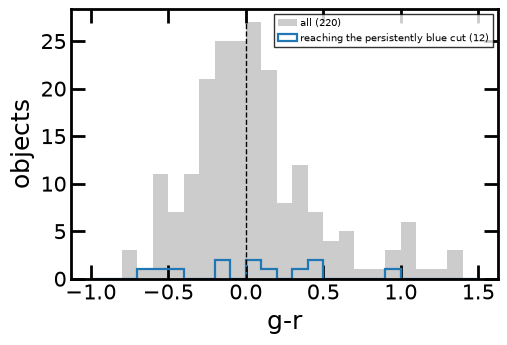

In [10]:
GR_MAX = 0.0          # <- your choice

fig, ax = plt.subplots(figsize=(5.5, 3.5))
plot_distribution(ax, "g-r", bins=np.arange(-1.0, 1.51, 0.1), threshold=GR_MAX)
print(f"with GR_MAX = {GR_MAX}: {len(cut_flow(verbose=False)[0])} candidates")

## Exercise 2 · Choose the timescale cuts

`MIN_AGE`, `MAX_AGE`, `MIN_COLOUR_EPOCHS` and `MIN_COLOUR_BASELINE` are yours.

These are the cuts that decide *when* you are willing to look at an object, and they
pull against each other. A long baseline measures a reddening rate well, but a TDE
discovered last week cannot have one, and that is exactly when follow-up is worth
triggering. A long `MAX_AGE` admits objects that have been varying for years, which is
what an AGN does.

*From the tutorial:* Wednesday's search required detections on multiple nights and in at
least two bands before measuring a rate, and tiered on `dm/dt`: faster than 0.3 mag/day
as kilonova-like, 0.05 to 0.3 as young or fast supernovae, slower than 0.05 discarded.
Everything here lives in that discarded bin.

**Steps.**

1. Plot the baseline distribution. The median object has about 8 days of colour
   coverage: is a cut at 20 days removing objects for their physics, or for how often
   this field was visited?
2. Do the same for the flare age and `MAX_AGE`.
3. Choose both, and say in your paragraph which one you would relax first if you had ten
   times as much follow-up time, and what would leak in.

*Go further:* measure `dm/dt` in r the way Wednesday's `ev_rate` did, and plot it
against `d(g-r)/dt`. Where do the four classified objects sit?

3 candidates


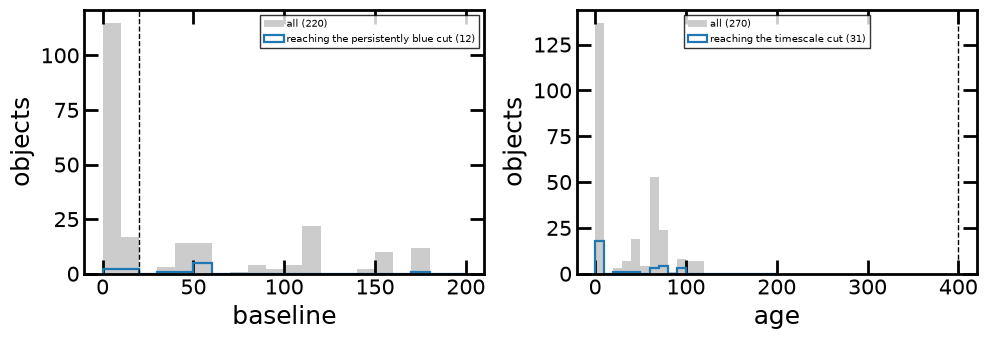

In [11]:
MIN_COLOUR_BASELINE = 20.0     # <- your choice
MAX_AGE = 400.0                # <- your choice

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.5))
plot_distribution(axes[0], "baseline", bins=np.arange(0.0, 200.1, 10.0),
                  threshold=MIN_COLOUR_BASELINE)
plot_distribution(axes[1], "age", bins=np.arange(0.0, 200.1, 10.0), threshold=MAX_AGE)
fig.tight_layout()
print(f"{len(cut_flow(verbose=False)[0])} candidates")

## Exercise 3 · Choose the nuclear cut

`NUCLEAR_ARCSEC`, `HOST_MAX_POINT_SCORE` and `STAR_MIN_POINT_SCORE` are yours.

"Nuclear" needs a catalogue to be nuclear *with respect to*, and the choice matters more
than the threshold. `is_nuclear` uses the Legacy Survey catalogue and its `score`, which the Setup section
measured against the broker's own star flag: below 0.5 nothing is flagged stellar, above
0.5 almost everything is. NED is the more familiar choice and is also available as
`host_galaxies`, with the advantage that a redshift turns an angular offset into a
physical one.

*From the tutorial:* sections 4.1 to 4.4 used a 3 arcsecond cross-match radius,
described there as nuclear-to-galaxy scale, and section 4.4 removed faint point sources
using a deep optical catalogue - the same idea as the `score` cut here.

**Steps.**

1. Plot the offset distribution. Note where the objects actually sit before choosing
   where to cut.
2. Plot the score distribution too. It is sharply bimodal, and your threshold has to
   land in the gap - the Setup measurement says which side is which.
3. Decide `HOST_MAX_POINT_SCORE` too: how confident do you need to be that the thing at
   the alert position is extended rather than a point source?

*Go further (optional):* rewrite `is_nuclear` in a new cell to use `host_galaxies` (NED)
instead of the Legacy Survey catalogue, and scan the same range. Plot both curves
together. Which catalogue can a search at this magnitude rely on, and what does the
answer tell you about how a selection fails?

3 candidates


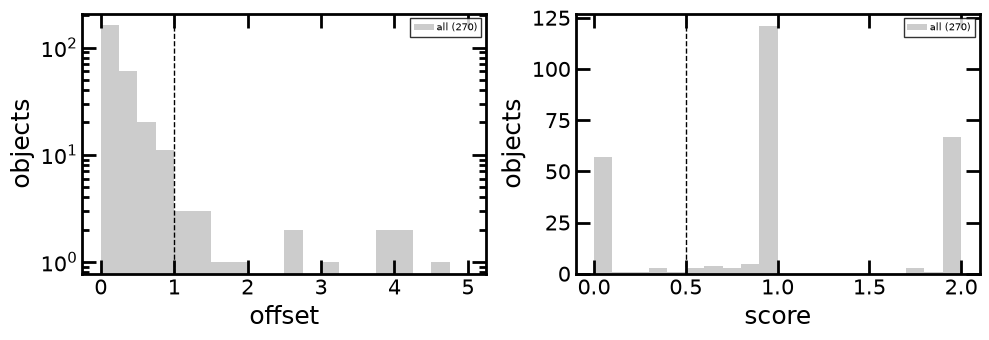

In [12]:
NUCLEAR_ARCSEC = 1.0           # <- your choice
HOST_MAX_POINT_SCORE = 0.5     # <- your choice

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.5))
plot_distribution(axes[0], "offset", bins=np.arange(0.0, 5.01, 0.25),
                  threshold=NUCLEAR_ARCSEC, log=True)
plot_distribution(axes[1], "score", bins=np.arange(0.0, 2.01, 0.1),
                  threshold=HOST_MAX_POINT_SCORE)
fig.tight_layout()
print(f"{len(cut_flow(verbose=False)[0])} candidates")

## Exercise 4 · What did you actually find?

Keep the placeholder thresholds, or your own from another exercise, and look at what
survives.

Photometry cannot classify a transient with certainty - that needs a spectrum - but it
constrains it. The reference is **van Velzen et al. (2021, ApJ 908, 4), Figure 1**,
which puts spectroscopically classified TDEs, supernovae and AGN as contours in the
quantities you have measured: rise and fade timescale, `g-r`, and colour evolution rate.

| class | light curve | colour | colour evolution |
|---|---|---|---|
| **TDE** | one smooth flare, long rise, decline often near a power law | blue | nearly none |
| **supernova** | one flare, faster rise and fade | blue only near peak | reddens as it cools |
| **AGN** | no single peak; wanders and recurs | blue | little, but stochastic |

Photometric TDE classification is genuinely hard: the ALeRCE classifier uses 176
light-curve features and its TDE predictions only become reliable above about 50 percent
confidence, with Type Ia supernovae the dominant confusion (Pavez-Herrera et al. 2025,
arXiv:2503.19698). A confident answer from a handful of light curves should make you
suspicious.

`light_curve_summary` is given: it returns the peak magnitude and when it falls in the
window, the rise and fade spans, the amplitude, the median photometric error, the colour
trend, and the number of post-peak re-brightenings that beat the errors.

**Steps.**

1. Run it on your survivors and read the numbers before plotting anything. Check the
   median error first: at these magnitudes it decides whether a wiggle is real.
2. Make the panel - either the light curves, or the objects in the `g-r` against
   `d(g-r)/dt` plane with the four classified objects for comparison.
3. In your paragraph, classify each survivor, and say which you cannot classify and why.
   "Not classifiable from this data" is a correct answer when it is true.

*Go further (optional):* `babamul.jupyter.scan_alerts(candidates)` pages through the
cutouts and light curves interactively.

In [13]:
candidates, _ = cut_flow()
for alert in candidates:
    print(alert.objectId, light_curve_summary(alert))

# Your panel here: the light curves, or g-r against d(g-r)/dt with CLASSIFIED for
# comparison.

                 cut   kept  removed
        quality cuts    270        -
             nuclear     48      222
          not an AGN     32       16
          not a star     31        1
           timescale     13       18
   persistently blue      3       10
313761042209439832 {'r_epochs': 95, 'span_d': 43.9, 'peak_r': 21.22, 'rise_d': 39.9, 'fade_d': 4.0, 'amplitude': 2.21, 'median_err': 0.031, 'g-r': -0.188, 'slope': -0.0102, 'slope_err': 0.0014, 'rebrightenings': 0}
313831458387001371 {'r_epochs': 118, 'span_d': 186.3, 'peak_r': 21.39, 'rise_d': 46.0, 'fade_d': 140.3, 'amplitude': 1.43, 'median_err': 0.034, 'g-r': -0.164, 'slope': -0.0037, 'slope_err': 0.0005, 'rebrightenings': 1}
313893023209488448 {'r_epochs': 144, 'span_d': 180.3, 'peak_r': 21.79, 'rise_d': 180.3, 'fade_d': 0.0, 'amplitude': 1.29, 'median_err': 0.088, 'g-r': -0.615, 'slope': 0.0011, 'slope_err': 0.0012, 'rebrightenings': 0}


## Hand-in

Turn in **this notebook** with: (1) one figure from the exercise
you chose; (2) one paragraph, starting with "Exercise N": what you set the threshold to,
why that value follows from the physics, and what it cost you - **quote at least one
number read off your figure**; (3) the AI-tools line below filled in. Graded
complete/incomplete.

Do the work in your exercise's cell, then paste the lines that draw the figure into the
cell below, so the figure sits next to the paragraph. Before you upload, choose *Run
All*, save, and download the .ipynb (File -> Download). Submit the notebook, not a PDF.

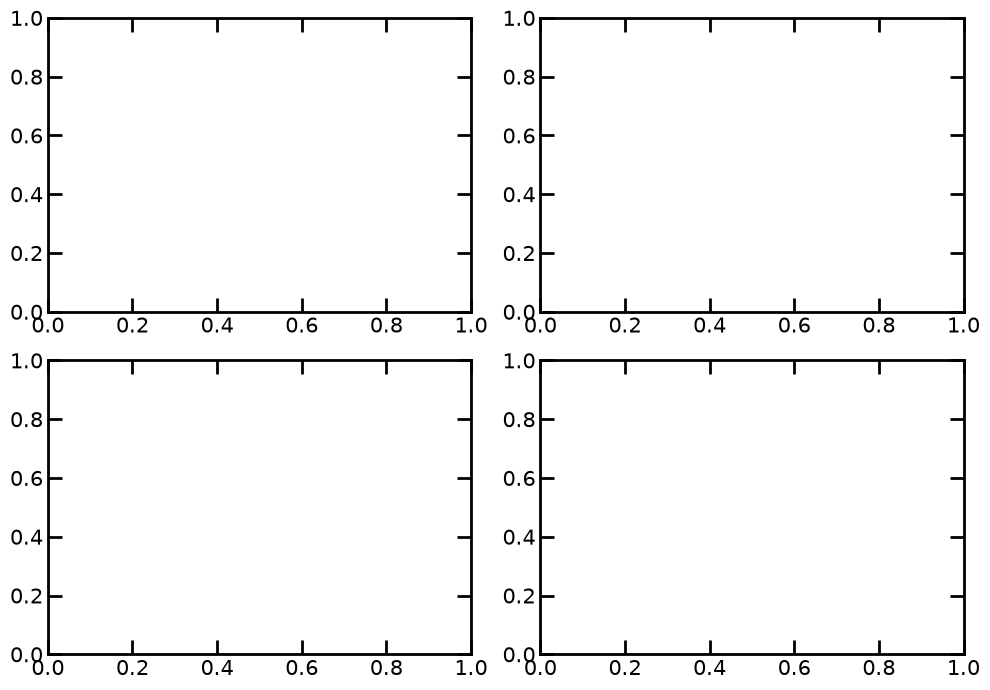

In [14]:
# Your hand-in figure: one panel per exercise.
fig, axes = plt.subplots(2, 2, figsize=(10.0, 7.0))

# axes[0, 0] -- Exercise 1, colour
# axes[0, 1] -- Exercise 2, timescale
# axes[1, 0] -- Exercise 3, nuclear
# axes[1, 1] -- Exercise 4, what you found

fig.tight_layout()

**Exercise N.** *Your paragraph here.*

**AI tools:** *none, or which ones and what for.*